<a href="https://colab.research.google.com/github/LikithaSrinivasa25/ml-dl-algorithms/blob/main/nlp/Text_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exp No:** 08

**Topic:** Text Clustering

**Aim:** Write a program to Implement Text Clustering using K-Means

**Data:** Text data sourced from https://timesofindia.indiatimes.com/?from=mdr

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import Normalizer
from sklearn import metrics
from collections import defaultdict
from sklearn.cluster import KMeans
from nltk.corpus import wordnet as wn
from sklearn import model_selection, naive_bayes, svm
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from nltk import pos_tag
import re
import warnings
warnings.filterwarnings("ignore")
from wordcloud import WordCloud
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


True

In [ ]:
data=open("/content/newsstudy.text")

In [ ]:
training_data = []

lemma =WordNetLemmatizer()
stopwords =stopwords.words("english")
for text in data:
  text = re.sub("[^a-zA-Z0-9]", " ", text)
  text = nltk.word_tokenize(text.lower())
  text = [lemma.lemmatize(word) for word in text]
  text = [word for word in text if word not in stopwords]
  text = " ".join(text)
  training_data.append(text)

In [ ]:
vector = TfidfVectorizer()
vec = vector.fit_transform(training_data)

In [ ]:
kmeans = KMeans(n_clusters=5, init='k-means++', max_iter=100)
kmeans.fit(vec)
centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
terms = vector.get_feature_names()
for i in range(5):
    print("Cluster %d:" % i, end='')
    for ind in centroids[i, :10]:
        print(' %s' % terms[ind], end='')
    print()


Cluster 0: skin hangover sun nagdev avoid sleep cause excessive pooja dark
Cluster 1: huawei license item udyan kantara film ha company administration people
Cluster 2: harassing deleted male picture twitter arsha sit friend monday incident
Cluster 3: india series australia test played condition bruyn team de different
Cluster 4: arrested guard tourist allegedly bengaluru woman 000 deployed bbmp extorting


In [ ]:
def frequencies_dict(cluster_index):
    if cluster_index > 5- 1:
        return
    term_frequencies = kmeans.cluster_centers_[cluster_index]
    sorted_terms = centroids[cluster_index]
    frequencies = {terms[i]: term_frequencies[i] for i in sorted_terms}
    return frequencies

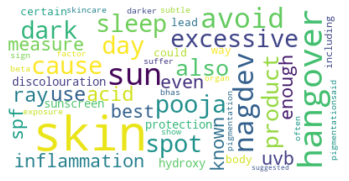

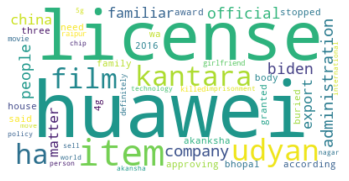

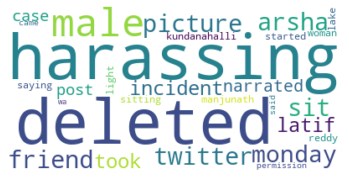

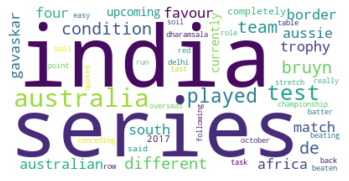

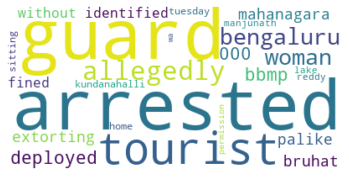

In [ ]:
def makeImage(frequencies):
    wc = WordCloud(background_color="white", max_words=50)
    wc.generate_from_frequencies(frequencies)
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.show()

for i in range(5):
    freq = frequencies_dict(i)
    makeImage(freq)
    print()

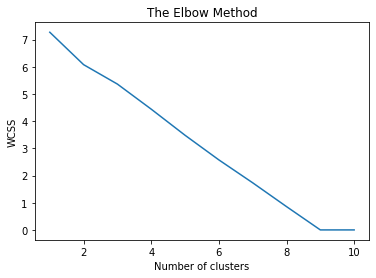

In [ ]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1,11):
    kms = KMeans(n_clusters=i,init='k-means++',max_iter=300,n_init=10,random_state=0)
    kms.fit(vec)
    wcss.append(kms.inertia_)
plt.plot(range(1,11),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

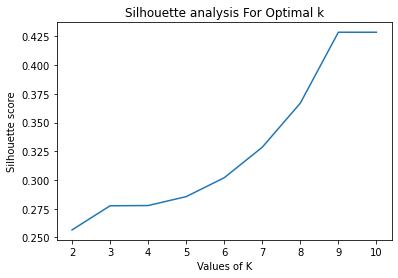

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_avg = []
for i in range(2,11):
 km = KMeans(n_clusters=i, init = 'k-means++', random_state =42)
 km.fit_predict(vec)
 silhouette_avg.append(silhouette_score(vec, km.labels_))

sns.lineplot(range(2,11),silhouette_avg)
plt.xlabel("Values of K")
plt.ylabel("Silhouette score")
plt.title("Silhouette analysis For Optimal k")
plt.show()

Cluster 0: huawei license item film kantara ha company administration people biden
Cluster 1: skin india woman udyan series wa australia arrested allegedly tourist


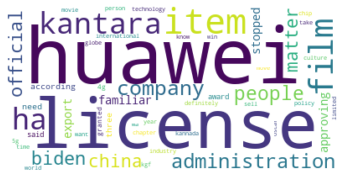

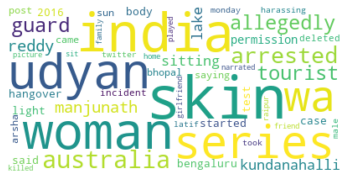

In [ ]:
kms = KMeans(n_clusters=2, init='k-means++', max_iter=100)
kms.fit(vec)
centroids = kms.cluster_centers_.argsort()[:, ::-1]
terms = vector.get_feature_names()
for i in range(2):
    print("Cluster %d:" % i, end='')
    for ind in centroids[i, :10]:
        print(' %s' % terms[ind], end='')
    print()

def frequencies_dict(cluster_index):
    if cluster_index > 2- 1:
        return
    term_frequencies = kms.cluster_centers_[cluster_index]
    sorted_terms = centroids[cluster_index]
    frequencies = {terms[i]: term_frequencies[i] for i in sorted_terms}
    return frequencies

def makeImage(frequencies):
    wc = WordCloud(background_color="white", max_words=50)
    wc.generate_from_frequencies(frequencies)
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.show()

for i in range(2):
    freq = frequencies_dict(i)
    makeImage(freq)
    print()

Cluster 0: india series film kantara huawei australia official said need ha
Cluster 1: udyan 2016 bhopal body girlfriend buried family akanksha killed raipur
Cluster 2: arrested guard tourist allegedly bengaluru woman 000 deployed bbmp extorting
Cluster 3: three according approving stopped matter biden export familiar administration company
Cluster 4: skin hangover sun nagdev avoid sleep cause excessive pooja dark
Cluster 5: harassing deleted male picture twitter arsha sit friend monday incident


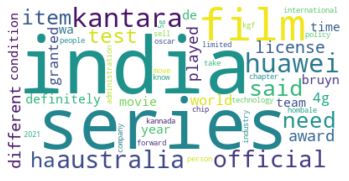

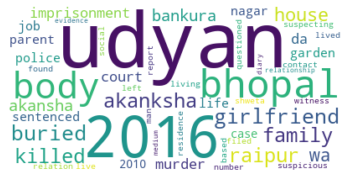

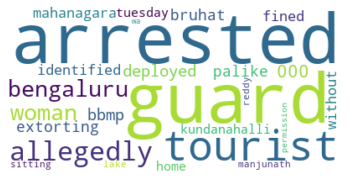

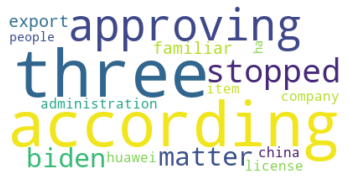

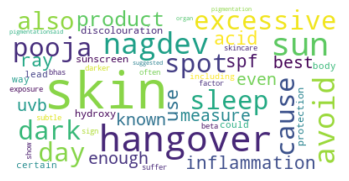

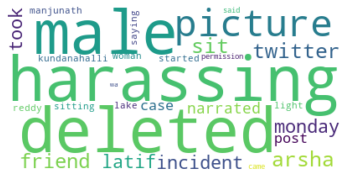

In [ ]:
kmns = KMeans(n_clusters=6, init='k-means++', max_iter=100)
kmns.fit(vec)
centroids = kmns.cluster_centers_.argsort()[:, ::-1]
terms = vector.get_feature_names()
for i in range(6):
    print("Cluster %d:" % i, end='')
    for ind in centroids[i, :10]:
        print(' %s' % terms[ind], end='')
    print()

def frequencies_dict(cluster_index):
    if cluster_index > 6- 1:
        return
    term_frequencies = kmns.cluster_centers_[cluster_index]
    sorted_terms = centroids[cluster_index]
    frequencies = {terms[i]: term_frequencies[i] for i in sorted_terms}
    return frequencies

def makeImage(frequencies):
    wc = WordCloud(background_color="white", max_words=50)
    wc.generate_from_frequencies(frequencies)
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.show()

for i in range(6):
    freq = frequencies_dict(i)
    makeImage(freq)
    print()

**Conclusion**: Text clustering is the application of cluster analysis to text-based documents.K-means clustering is a type of unsupervised learning method, which is used when we don't have labeled data, we have unlabeled data (means, without defined categories or groups). The goal of this algorithm is to find groups in the data, whereas the no. of groups is represented by the variable K.